In [1]:
import os, re, sys, gc, json, shutil, cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

sys.path.append('../../Model')                 # Network/, utils/ vivem em Model/
from Network.index import ModelNetwork

cv2.setNumThreads(1)                        # O DATALOADER CRIA WORKERS POR FORK DEPOIS DO CV2: SEM ISSO OS FILHOS TRAVAM
pd.set_option('display.max_columns', None)

In [2]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

gc.collect()
print(torch.__version__)              # versão do PyTorch
print(torch.cuda.is_available())      # True se detectou a GPU

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))  # nome da GPU

2.7.1+cu128
True
NVIDIA GeForce RTX 5070


### CONFIGURAÇÃO
- `BASE_PATH` é a pasta dos modelos (`model_N/` com `info.json` e `model.pth`); `MODELS = []` pega todos os `model_N` dela
- `FULL_PREDICT = False` prediz só os 32 × 28 = 896 tiles cujo núcleo cobre a `INLINE` (~7 GB e poucos minutos por modelo); `True` prediz o bloco inteiro (38 528 tiles, ~308 GB e ~4,9 h por modelo)
- `OVERLAP` e `WINDOW` controlam a janela deslizante; `WINDOW = None` usa a janela em que a rede foi treinada
- `STICK_TOL`, `STICK_MIN` e `STICK_GAP` são os botões do extrator, os mesmos calibrados no Marlim (mergulho aceito de 43° a 76°)

In [3]:
BASE_PATH   = '../../Documents/Backups/Multiscale/'    # PASTA DOS MODELOS: '../../Model/Backup', '../../Documents/Backups/Marcia', ...
IRACEMA_DIR = 'files/patches'                      # O BLOCO INTEIRO, UM .DAT POR TILE
META_PATH   = 'files/patch_metadata.json'
CACHE_DIR   = 'files/cache'
OUTPUT_DIR  = f'{BASE_PATH}/outputs/iracema'       # FIGURAS E TABELA DE TODOS OS MODELOS SELECIONADOS

MODELS       = ['model_1']   # [] = TODOS OS MODELOS DE BASE_PATH
INLINE       = 1375          # INLINE DAS FIGURAS (0 A 2750)
FULL_PREDICT = True         # False PREDIZ SÓ OS TILES QUE COBREM A INLINE; True O BLOCO INTEIRO
VOLUME       = False         # True GRAVA O predicted.npy DO BLOCO INTEIRO (~38,6 GB, PEDE FULL_PREDICT)
OVERLAP      = 0.25          # SOBREPOSIÇÃO ENTRE JANELAS (0 = CORTE SECO, DO JEITO QUE O FORMAT CORTA O TREINO)
WINDOW       = None          # None = A JANELA DO TREINO (info.json); FORCE UMA TUPLA PARA TESTAR OUTRA, EX: (64, 64, 64)
SKIP_DONE    = True          # True PULA O TILE QUE JÁ TEM MÁSCARA: UMA RODADA INTERROMPIDA CONTINUA DE ONDE PAROU
MODEL_THRESHOLD = 0.5

STICK_TOL = 0.80    # PERMISSIVIDADE DO EXTRATOR: 0 SÓ O TRAÇO ÓBVIO, 1 TUDO QUE PARECER FALHA
STICK_MIN = 140     # PX
STICK_GAP = 59      # PX: MAIOR LACUNA COSTURADA DENTRO DE UM STICK

models = MODELS or sorted((m for m in os.listdir(BASE_PATH) if re.fullmatch(r'model_\d+', m)), key=lambda n: int(n.split('_')[-1]))
models

['model_1']

In [4]:
# RESUMO DO MODELO PELO INFO.JSON, COM A JANELA DE TREINO NO RÓTULO
def modelSummary(name):
    path = f'{BASE_PATH}/{name}/info.json'
    info = json.load(open(path)) if os.path.exists(path) else {}

    size    = info.get('model', {}).get('img_size')
    size    = [] if size is None else ([size] * 3 if np.isscalar(size) else list(size))
    network = info.get('model', {}).get('network', '?')
    window  = '×'.join(str(int(s)) for s in size) if size else '?'
    iou     = info.get('trainer', {}).get('test_iou')

    return {
        'nome': name,
        'rede': network,
        'janela': window,
        'dataset': info.get('processing', {}).get('dataset', '?'),
        'iou_teste': round(float(iou), 4) if iou is not None else None,
        'rotulo': f'{name} · {network} {window}' + (f' (iou={iou:.3f})' if iou is not None else '')
    }


pd.DataFrame([modelSummary(m) for m in models])

,nome,rede,janela,dataset,iou_teste,rotulo
0,model_1,dbrnet,128×128×128,dataset_74_wu,0.7568,model_1 · dbrnet 128×128×128 (iou=0.757)


### TILES
- `TileGrid` lê um `patch_metadata.json` e sabe onde o núcleo de cada tile (o tile sem os 32 voxels de borda) cai no volume, no mesmo corte em que os tiles foram gerados
- `names(inline)` lista os tiles do grid, todos ou só os que têm o núcleo sobre uma inline; `missing(pasta, inline)` diz quais deles ainda não têm arquivo inteiro na pasta (um `.dat` cortado no meio conta como faltando)
- `reconstruct` monta o volume, ou só uma inline, pelos núcleos; o shape vem do metadata, nunca da janela do modelo, e um tile faltando levanta erro em vez de deixar buraco zerado

In [5]:
# ESCALAR OU LISTA VIRA TUPLA DE 3 EIXOS, PARA JANELA E TILE ENTRAREM NO MESMO FORMATO
def asTriple(value, default=None):
    value = default if value is None else value
    value = [value] * 3 if np.isscalar(value) else list(value)

    if len(value) != 3:
        raise ValueError(f'esperado 3 eixos, recebido {value}')

    return tuple(int(v) for v in value)


# LÊ O .DAT CRU NO SHAPE DO TILE (NÃO É FIXO EM 128³)
def getDAT(path, shape):
    data = np.fromfile(path, dtype=np.float32)

    if data.size != int(np.prod(shape)):
        raise ValueError(f'{os.path.basename(path)}: {data.size} valores, esperado {tuple(shape)}')

    return data.reshape(shape)


# SERVE OS TILES UM A UM, NO SHAPE DECLARADO NO PATCH_METADATA
class PredictDataset(Dataset):
    def __init__(self, paths, shape):
        self.paths = paths
        self.shape = asTriple(shape)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return torch.from_numpy(getDAT(self.paths[index], self.shape))


# GRADE DE TILES DE UM PATCH_METADATA: QUAIS TILES EXISTEM E ONDE O NÚCLEO DE CADA UM CAI NO VOLUME
class TileGrid:
    def __init__(self, metaPath):
        meta        = json.load(open(metaPath))
        self.size   = asTriple(meta['patch_size'])
        self.ov     = asTriple(meta['overlap_voxels'])
        self.shape  = tuple(meta['original_shape'])
        self.counts = tuple(meta['grid_shape'])
        self.stride = tuple(p - 2 * o for p, o in zip(self.size, self.ov))
        self.last   = [n // s for n, s in zip(self.shape, self.stride)]

    # NOMES DOS TILES DO GRID; COM inline, SÓ OS QUE TÊM O NÚCLEO SOBRE ELA
    def names(self, inline=None):
        names = [f'patch_d{d:03d}_h{h:03d}_w{w:03d}.dat' for d, h, w in np.ndindex(*self.counts)]
        return names if inline is None else [n for n in names if self.covers(n, inline)]

    # TILES SEM ARQUIVO INTEIRO EM folder (UM .DAT CORTADO NO MEIO CONTA COMO FALTANDO)
    def missing(self, folder, inline=None):
        size = 4 * int(np.prod(self.size))
        return [n for n in self.names(inline) if not (os.path.exists(f'{folder}/{n}') and os.path.getsize(f'{folder}/{n}') == size)]

    # ORIGEM E TAMANHO DO NÚCLEO DE UM TILE NO VOLUME, PELO ÍNDICE NO NOME; O ÚLTIMO DE CADA EIXO ENCOSTA NO FIM
    def core(self, name):
        index  = map(int, re.match(r'patch_d(\d+)_h(\d+)_w(\d+)\.dat', name).groups())
        origin = [max(0, n - s) if i == last else i * s for i, last, n, s in zip(index, self.last, self.shape, self.stride)]
        sizes  = [min(s, n - o) for s, n, o in zip(self.stride, self.shape, origin)]
        return origin, sizes

    def covers(self, name, inline):
        (d, _, _), (cd, _, _) = self.core(name)
        return d <= inline < d + cd

    # MONTA O VOLUME (OU SÓ A INLINE) PELOS NÚCLEOS DOS TILES DE folder; out RECEBE UM MEMMAP QUANDO O VOLUME NÃO CABE NA MEMÓRIA
    def reconstruct(self, folder, desc='montando', inline=None, out=None):
        missing = self.missing(folder, inline)

        if missing:
            raise FileNotFoundError(f'{folder}: faltam {len(missing)} de {len(self.names(inline))} tiles, predição incompleta')

        vol    = out if out is not None else np.zeros(self.shape if inline is None else self.shape[1:], np.float32)
        lo, hi = self.ov, [p - o for p, o in zip(self.size, self.ov)]

        for name in tqdm(self.names(inline), desc=desc):
            (d, h, w), (cd, ch, cw) = self.core(name)
            core = getDAT(f'{folder}/{name}', self.size)[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]

            if inline is None:
                vol[d:d + cd, h:h + ch, w:w + cw] = core[:cd, :ch, :cw]
            else:
                vol[h:h + ch, w:w + cw] = core[inline - d, :ch, :cw]

        return vol


grid = TileGrid(META_PATH)
{'shape': grid.shape, 'tiles': len(grid.names()), 'tiles_da_inline': len(grid.names(INLINE)), 'stride': grid.stride}

{'shape': (2751, 2000, 1754),
 'tiles': 38528,
 'tiles_da_inline': 896,
 'stride': (64, 64, 64)}

### JANELA DE INFERÊNCIA

In [6]:
class SlidingWindow:
    BUDGET    = 128 ** 3   # voxels por lote na GPU
    MAX_BATCH = 256

    def __init__(self, window, shape, overlap=OVERLAP):
        self.tile    = asTriple(shape)
        self.window  = asTriple(window)
        self.overlap = float(overlap)

        self.shape  = tuple(max(t, w) for t, w in zip(self.tile, self.window))   # tile menor que a janela -> reflect
        self.pad    = tuple(s - t for s, t in zip(self.shape, self.tile))
        self.starts = [self.getStarts(s, w) for s, w in zip(self.shape, self.window)]

        self.positions = [(d, h, w) for d in self.starts[0] for h in self.starts[1] for w in self.starts[2]]
        self.weight    = self.getWeight(self.window)
        self.batch     = int(np.clip(self.BUDGET // int(np.prod(self.window)), 1, self.MAX_BATCH))

    # INÍCIO DE CADA JANELA NUM EIXO; A ÚLTIMA ENCOSTA NO FIM DO TILE
    def getStarts(self, size, window):
        step = max(int(round(window * (1 - self.overlap))), 1)
        return sorted(set(list(range(0, size - window + 1, step)) + [size - window]))

    # PESO 3D SEPARÁVEL, ~1 NO CENTRO DA JANELA E ~0 NA BORDA, PARA A EMENDA NÃO VIRAR DEGRAU
    @staticmethod
    def getWeight(window):
        d, h, w = [np.hanning(n + 2)[1:-1].astype(np.float32) for n in window]
        return np.maximum(d[:, None, None] * h[None, :, None] * w[None, None, :], 1e-3)

    # PROBABILIDADE DO TILE INTEIRO, SOMANDO AS JANELAS PONDERADAS PELO PESO
    def process(self, network, tile):
        volume = tile.numpy() if torch.is_tensor(tile) else np.asarray(tile)
        volume = np.pad(volume, [(0, p) for p in self.pad], mode='reflect') if any(self.pad) else volume
        volume = torch.from_numpy(np.ascontiguousarray(volume, np.float32)).to(network.device)

        weight = torch.from_numpy(self.weight).to(network.device)
        total  = torch.zeros((network.classes, *self.shape), dtype=torch.float32, device=network.device)
        norm   = torch.zeros(self.shape, dtype=torch.float32, device=network.device)
        wd, wh, ww = self.window

        with torch.no_grad():
            for start in range(0, len(self.positions), self.batch):
                chunk  = self.positions[start:start + self.batch]
                batch  = torch.stack([volume[d:d + wd, h:h + wh, w:w + ww] for d, h, w in chunk]).unsqueeze(1)
                logits = network.model(batch)
                probs  = torch.softmax(logits, dim=1) if network.multiclass else torch.sigmoid(logits)

                for i, (d, h, w) in enumerate(chunk):
                    total[:, d:d + wd, h:h + wh, w:w + ww] += probs[i].float() * weight
                    norm[d:d + wd, h:h + wh, w:w + ww]     += weight

        probs = (total / norm).cpu().numpy().astype(np.float32)
        probs = probs[0] if network.classes == 1 else probs
        return probs[..., :self.tile[0], :self.tile[1], :self.tile[2]]

    def __repr__(self):
        return (f'SlidingWindow(janela={self.window}, tile={self.tile}, overlap={self.overlap}, 'f'janelas/tile={len(self.positions)}, batch={self.batch})')


SlidingWindow(window=(32, 32, 32), shape=128)

SlidingWindow(janela=(32, 32, 32), tile=(128, 128, 128), overlap=0.25, janelas/tile=125, batch=64)

### PREDIÇÃO
- `IracemaPredictor` cuida de um modelo: carrega os pesos só quando algum tile está pendente, e só se o `scaling` do treino for `'normalize'` ou `'percentile'` (o Iracema está em `[0, 1]`)
- `predict()` passa os tiles pendentes pela `SlidingWindow` (só os da `INLINE`, ou todos com `FULL_PREDICT`), grava `masks/` e `predict.json` e devolve quantos tiles saíram agora; a tabela abaixo é o que falta predizer

In [7]:
# UM MODELO SALVO NO BLOCO DE IRACEMA: A REDE SÓ É CARREGADA QUANDO HÁ TILE PENDENTE
class IracemaPredictor:
    def __init__(self, modelName, base=BASE_PATH, overlap=OVERLAP, window=WINDOW, skipDone=SKIP_DONE, inline=None if FULL_PREDICT else INLINE):
        self.modelName = modelName
        self.modelPath = f'{base}/{modelName}'
        self.overlap   = overlap
        self.window    = window
        self.skipDone  = skipDone
        self.inline    = inline
        self.network   = None

    # PASTA DOS TILES .DAT DO BLOCO; O PATCH_METADATA FICA EM files/
    def inputDir(self):
        return IRACEMA_DIR

    # PASTA DA PREDIÇÃO DO BLOCO: masks/, predict.json, predicted.npy E AS FIGURAS
    def outputDir(self):
        return f'{self.modelPath}/iracema'

    def grid(self):
        return TileGrid(META_PATH)

    # TILES DO BLOCO (OU SÓ OS DA INLINE) QUE FALTAM PREDIZER; COM SKIP_DONE, OS QUE JÁ TÊM MÁSCARA INTEIRA FICAM DE FORA
    def pending(self):
        return self.grid().missing(f'{self.outputDir()}/masks', self.inline) if self.skipDone else self.grid().names(self.inline)

    # PREDIZ OS TILES PENDENTES DO BLOCO E DEVOLVE QUANTOS FORAM PREDITOS AGORA
    def predict(self):
        names = self.pending()

        if not names:
            print(f'[{self.modelName}] iracema já predito — pulando')
            return 0

        if not self.load():
            return 0

        sliding = self.run(self.grid(), self.inputDir(), self.outputDir(), names, 'iracema')
        self.export(self.outputDir(), sliding, block='iracema', inline=self.inline, tiles=len(self.grid().names(self.inline)))
        return len(names)

    # CARREGA OS PESOS UMA VEZ, COM A JANELA EM QUE A REDE FOI TREINADA; False QUANDO O MODELO NÃO SERVE PARA O BLOCO
    def load(self):
        if self.network is not None:
            return True

        if not os.path.exists(f'{self.modelPath}/model.pth'):
            print(f'[{self.modelName}] sem model.pth — pulando')
            return False

        info    = json.load(open(f'{self.modelPath}/info.json', encoding='utf-8'))
        options = info.get('model', {})
        scaling = info.get('processing', {}).get('scaling', 'normalize')

        # O BLOCO ESTÁ EM [0, 1]: SÓ SE APLICA A MODELO TREINADO EM DADO NESSA ESCALA (scaling 'normalize' OU 'percentile' NO info.json)
        if scaling not in ('normalize', 'percentile'):
            print(f'[{self.modelName}] treinado com scaling={scaling!r}, fora de [0, 1] — pulando')
            return False

        print(f'[{self.modelName}] Model Options:')
        print(json.dumps(options, indent=4))

        self.network = ModelNetwork(**options)
        self.network.model.load_state_dict(torch.load(f'{self.modelPath}/model.pth', map_location=self.network.device)['model'])
        self.network.model.eval()
        self.window = asTriple(self.window or options.get('img_size'), default=128)
        print(f'Weights from {self.modelPath} loaded successfully!\n')
        return True

    # PREDIZ OS TILES names DE inputDir PELA JANELA DESLIZANTE, UMA MÁSCARA POR TILE EM outputDir/masks NO SHAPE DA ENTRADA
    def run(self, grid, inputDir, outputDir, names, tag):
        sliding = SlidingWindow(self.window, grid.size, overlap=self.overlap)
        dataset = PredictDataset([f'{inputDir}/{name}' for name in names], grid.size)
        loader  = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
        os.makedirs(f'{outputDir}/masks', exist_ok=True)

        print(f'[{self.modelName}] {tag}: {sliding} — {len(names)} tiles pendentes')

        if len(sliding.positions) == 1:
            print(f'[{self.modelName}] janela == tile: uma passada por tile — OVERLAP={self.overlap} e o peso Hann não têm efeito aqui')

        for name, tile in zip(names, tqdm(loader, desc=f'{self.modelName} - {tag}')):
            sliding.process(self.network, tile[0]).tofile(f'{outputDir}/masks/{name}')

        print(f'Predições de {self.modelName} - {tag} salvas em {outputDir}/masks')
        return sliding

    # REGISTRA A JANELA USADA, QUE A TABELA DO FIM LÊ
    def export(self, outputDir, sliding, **fields):
        info = {'model': self.modelName, **fields, 'tile_shape': list(sliding.tile), 'img_size': list(sliding.window), 'overlap': sliding.overlap, 'windows_per_tile': len(sliding.positions)}
        json.dump(info, open(f'{outputDir}/predict.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=4)

    # SOLTA A REDE E A MEMÓRIA DA GPU ANTES DO PRÓXIMO MODELO
    def release(self):
        self.network = None
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


pd.DataFrame([{'modelo': m, 'inline': INLINE if not FULL_PREDICT else 'todas', 'pendentes': len(IracemaPredictor(m).pending())} for m in models])

,modelo,inline,pendentes
0,model_1,todas,38528


# EXTRAÇÃO DE STICKS
- Cada falha de uma seção 2D vira uma reta (**stick**), a mesma representação para a rede e para o especialista
- **Evidência**: a probabilidade suavizada e reescalada para $[0,1]$; o piso sobe pelo percentil quando a predição é densa, para a teia não explodir o traçado
- **Votação tipo Hough**: a evidência somada numa janela reta de `seedLen` px em cada orientação plausível; os picos são as sementes
- **Traçado**: a semente se estende enquanto houver suporte, tolerando lacunas de até `STICK_GAP` px, e a reta é reajustada ao centro de massa da evidência por **PCA**
- **Filtros**: mergulho entre 43° e 76°, comprimento mínimo `STICK_MIN`, preenchimento, **energia sísmica** (a falha precisa cortar refletores, não a água nem a zona morta) e **ângulo com as camadas** pelo tensor de estrutura
- **Matching pursuit**: aceita a melhor reta, consome o corredor dela e segue para a próxima; no fim, retas colineares se fundem e as que correm por cima de uma maior saem

In [8]:
# FALHAS DE UMA SEÇÃO 2D COMO RETAS: VOTAÇÃO TIPO HOUGH, TRAÇADO COM LACUNAS, PCA E MATCHING PURSUIT
class FaultStickExtractor:
    def __init__(self, tolerance=STICK_TOL, minLen=STICK_MIN, maxGap=STICK_GAP):
        t    = float(np.clip(tolerance, 0.0, 1.0))
        lerp = lambda a, b: a + (b - a) * t

        self.tolerance = t
        self.minLen    = float(minLen)
        self.maxGap    = int(maxGap)
        self.dipMin    = 43.0
        self.dipMax    = 76.0

        self.evSigma  = 1.0
        self.evBudget = 0.020    # FRAÇÃO DA SEÇÃO QUE SE ESPERA MARCADA; ACIMA DISSO O PISO SOBE
        self.evLo     = 0.20
        self.evHi     = 0.50

        self.scanMin   = 34.0    # VARREDURA UM POUCO MAIS LARGA QUE O MERGULHO ACEITO, PARA O PCA TER DE ONDE GIRAR
        self.angleStep = 3.0
        self.seedLen   = 140
        self.seedWidth = 5
        self.seedThr   = lerp(0.198, 0.048)
        self.maxSeeds  = 1200
        self.nmsOffset = 9
        self.nmsAlong  = 51
        self.nmsAngle  = 9.9

        self.corrWidth    = 5
        self.supThr       = lerp(0.381, 0.211)
        self.traceMax     = 560
        self.stretchGap   = 86
        self.stretchFill  = 0.385
        self.stretchWidth = 8
        self.consumeWidth = 4

        self.minFill     = lerp(0.615, 0.415)
        self.energyMin   = 0.167
        self.energyFrac  = 0.213
        self.energySigma = 25
        self.layerMin    = lerp(35.8, 25.8)
        self.layerSigma  = 12.0

        self.mergeAngle  = 8.65
        self.mergeOffset = 6.0
        self.mergeGap    = 157.0
        self.dupCover    = 0.722
        self.dupOffset   = 17.7

        self.layer = self.coh = self.energyMap = None

    # STICKS DE UM MAPA DE PROBABILIDADE; A SÍSMICA LIGA OS FILTROS DE ENERGIA E DE CORTE DAS CAMADAS
    def extract(self, prob, seismic=None):
        self.energyMap = self.energy(seismic) if seismic is not None else None
        self.layer, self.coh = self.layering(seismic) if seismic is not None else (None, None)

        q = self.evidence(prob)
        return self.build(q, self.votes(q))

    # DA EVIDÊNCIA AOS STICKS FINAIS: PERSEGUIR, FUNDIR, REMEDIR O PREENCHIMENTO E TIRAR OS REPETIDOS
    def build(self, q, votes):
        sticks = self.merge(self.pursue(q, q.copy(), self.seeds(votes)))

        for s in sticks:
            s['fill'] = self.fracAbove(q, s, self.supThr)

        sticks = [s for s in sticks if s['len'] >= self.minLen and s['fill'] >= self.minFill * 0.9]
        return sorted(self.dedup(sticks), key=lambda s: -s['len'])

    # MATCHING PURSUIT: ACEITA A MELHOR RETA, CONSOME O CORREDOR DELA, SEGUE PARA A PRÓXIMA
    def pursue(self, q, res, seeds):
        sticks = []

        for score, x, y, phi in seeds:
            s = self.trace(res, x, y, phi)

            if s is None:
                continue

            s = self.refine(q, s)
            s['fill'] = self.fracAbove(res, s, self.supThr)

            if not self.accept(s):
                continue

            s = self.refine(q, self.stretch(res, s))
            self.consume(res, s)
            sticks.append(s)

        return sticks

    # PROBABILIDADE -> EVIDÊNCIA EM [0,1]; O PISO SOBE PELO PERCENTIL PARA A PREDIÇÃO DENSA NÃO EXPLODIR O TRAÇADO
    def evidence(self, prob):
        p  = gauss(prob.astype(np.float32), self.evSigma)
        hi = max(self.evHi, float(np.percentile(p, 100 * (1 - self.evBudget))))
        lo = max(self.evLo, float(np.percentile(p, 100 * (1 - 2 * self.evBudget))))
        return np.clip((p - lo) / max(hi - lo, 1e-3), 0, 1).astype(np.float32)

    # AMPLITUDE LOCAL DA SÍSMICA: ~0 NA ÁGUA E NA ZONA MORTA, ~1 NOS REFLETORES
    def energy(self, seismic):
        sec = seismic.astype(np.float32)
        mu  = gauss(sec, self.energySigma)
        var = gauss(sec * sec, self.energySigma) - mu * mu
        E   = np.sqrt(np.clip(var, 0, None))
        return np.clip(E / (np.percentile(E, 95) + 1e-9), 0, 1).astype(np.float32)

    # TENSOR DE ESTRUTURA DA SÍSMICA -> (ÂNGULO DAS CAMADAS EM GRAUS, COERÊNCIA)
    def layering(self, seismic):
        sec = seismic.astype(np.float32)
        Ix  = cv2.Sobel(sec, cv2.CV_32F, 1, 0, ksize=3)
        Iy  = cv2.Sobel(sec, cv2.CV_32F, 0, 1, ksize=3)
        Jxx, Jyy, Jxy = gauss(Ix * Ix, self.layerSigma), gauss(Iy * Iy, self.layerSigma), gauss(Ix * Iy, self.layerSigma)

        angle = (np.degrees(0.5 * np.arctan2(2 * Jxy, Jxx - Jyy)) + 90.0) % 180.0
        coh   = np.sqrt((Jxx - Jyy) ** 2 + 4 * Jxy ** 2) / (Jxx + Jyy + 1e-9)
        return angle.astype(np.float32), coh.astype(np.float32)

    # VOTAÇÃO TIPO HOUGH: EVIDÊNCIA MÉDIA NUMA JANELA RETA, PARA CADA ORIENTAÇÃO PLAUSÍVEL
    def votes(self, q):
        canvas = int(np.ceil(np.hypot(*q.shape)))
        ones   = np.ones_like(q)
        kernel = (self.seedWidth, self.seedLen)
        area   = kernel[0] * kernel[1]
        out    = []

        for phi in np.arange(self.scanMin, 180.0 - self.scanMin + 1e-6, self.angleStep):
            M = self.rotation(q.shape, phi - 90.0, canvas)
            R = cv2.warpAffine(q, M, (canvas, canvas), flags=cv2.INTER_LINEAR, borderValue=0)
            V = cv2.warpAffine(ones, M, (canvas, canvas), flags=cv2.INTER_NEAREST, borderValue=0)

            num = cv2.boxFilter(R, -1, kernel, normalize=False, borderType=cv2.BORDER_CONSTANT)
            den = cv2.boxFilter(V, -1, kernel, normalize=False, borderType=cv2.BORDER_CONSTANT)
            acc = np.where(den > 0.6 * area, num / np.maximum(den, 1e-6), 0)

            peak   = acc >= cv2.dilate(acc, np.ones((self.seedLen // 2, 9), np.uint8))
            ys, xs = np.nonzero((acc >= self.seedThr) & peak)

            if not len(ys):
                continue

            inv = cv2.invertAffineTransform(M)
            pts = inv[:, :2] @ np.stack([xs, ys]).astype(np.float32) + inv[:, 2:3]
            out += [(float(s), float(x), float(y), float(phi)) for (x, y), s in zip(pts.T, acc[ys, xs])]

        out.sort(key=lambda r: -r[0])
        return out

    # ROTAÇÃO QUE DEIXA UMA RETA DE ÂNGULO phi VERTICAL NUMA TELA QUADRADA
    @staticmethod
    def rotation(shape, angle, canvas):
        h, w = shape
        M = cv2.getRotationMatrix2D(((w - 1) / 2, (h - 1) / 2), angle, 1.0)
        M[0, 2] += (canvas - 1) / 2 - (w - 1) / 2
        M[1, 2] += (canvas - 1) / 2 - (h - 1) / 2
        return M

    # DESCARTA VOTOS REDUNDANTES: A DISTÂNCIA QUE IMPORTA É A PERPENDICULAR, PORQUE A FAMÍLIA DOMINÓ É PARALELA
    def seeds(self, votes):
        cell, kept, grid = self.nmsAlong, [], {}

        for seed in votes:
            score, x, y, phi = seed
            gx, gy = int(x // cell), int(y // cell)
            near   = [kept[k] for i in (gx - 1, gx, gx + 1) for j in (gy - 1, gy, gy + 1) for k in grid.get((i, j), ())]

            if any(self.redundant(seed, other) for other in near):
                continue

            grid.setdefault((gx, gy), []).append(len(kept))
            kept.append(seed)

            if len(kept) >= self.maxSeeds:
                break

        return kept

    def redundant(self, seed, other):
        _, x, y, phi    = seed
        _, x2, y2, phi2 = other
        da = abs(phi - phi2) % 180

        if min(da, 180 - da) > self.nmsAngle:
            return False

        d = np.array([np.cos(np.radians(phi2)), np.sin(np.radians(phi2))])
        v = np.array([x - x2, y - y2])
        return abs(d[0] * v[1] - d[1] * v[0]) <= self.nmsOffset and abs(d @ v) <= self.nmsAlong

    # ESTENDE A SEMENTE ENQUANTO HOUVER SUPORTE, TOLERANDO LACUNAS: É ISSO QUE COSTURA OS PEDAÇOS
    def trace(self, q, x, y, phi):
        d  = np.array([np.cos(np.radians(phi)), np.sin(np.radians(phi))])
        c  = np.array([x, y], float)
        ts = np.arange(-self.traceMax, self.traceMax + 1.0)

        prof, inside = self.profile(q, c, d, ts)
        sup  = (prof >= self.supThr) & inside
        i0   = len(ts) // 2
        half = self.seedLen // 2

        if not sup[max(i0 - half, 0):i0 + half + 1].any():
            return None

        a, b = self.extent(sup, i0, self.maxGap)

        if b - a < self.minLen * 0.6:
            return None

        return self.stick(c + ts[a] * d, c + ts[b] * d, sup[a:b + 1].mean())

    # PROCURA A CONTINUAÇÃO ALÉM DAS PONTAS: DEPOIS DE VALIDADA A RETA VALE ATRAVESSAR UMA LACUNA MAIOR
    def stretch(self, q, s):
        c, d, length = self.unit(s)
        ts = np.arange(-self.traceMax, self.traceMax + 1.0)
        prof, inside = self.profile(q, c, d, ts, self.stretchWidth)
        sup = (prof >= self.supThr) & inside

        i0   = len(ts) // 2
        a0   = max(int(i0 - length / 2), 0)
        b0   = min(int(i0 + length / 2), len(ts) - 1)
        a, b = self.extent(sup, i0, int(self.stretchGap))

        if a < a0 and sup[a:a0].mean() < self.stretchFill:
            a = a0

        if b > b0 and sup[b0:b].mean() < self.stretchFill:
            b = b0

        return self.stick(c + ts[a] * d, c + ts[b] * d, sup[a:b + 1].mean())

    # REAJUSTA A RETA AO CENTRO DE MASSA DA EVIDÊNCIA DENTRO DO CORREDOR
    def refine(self, q, s, iters=2):
        for _ in range(iters):
            c, d, length = self.unit(s)

            if length < 4:
                return s

            n    = np.array([-d[1], d[0]])
            ts   = np.arange(-length / 2, length / 2 + 1.0)
            offs = np.arange(-self.corrWidth, self.corrWidth + 1)
            X    = c[0] + ts[:, None] * d[0] + offs[None, :] * n[0]
            Y    = c[1] + ts[:, None] * d[1] + offs[None, :] * n[1]

            xi, yi = X.round().astype(np.int32), Y.round().astype(np.int32)
            ok     = (yi >= 0) & (yi < q.shape[0]) & (xi >= 0) & (xi < q.shape[1])
            w      = np.zeros(X.shape, np.float32)
            w[ok]  = q[yi[ok], xi[ok]]

            if w.sum() < 1e-3:
                return s

            wf    = w.ravel()
            P     = np.stack([X.ravel(), Y.ravel()])
            cm    = (P * wf).sum(1) / wf.sum()
            P0    = P - cm[:, None]
            V     = np.linalg.eigh((P0 * wf) @ P0.T / wf.sum())[1]
            dn    = V[:, -1] * (1 if V[1, -1] >= 0 else -1)

            if abs(float(dn @ d)) < 0.985:    # REJEITA GIROS BRUSCOS
                return s

            t = dn @ P0
            s = self.stick(cm + dn * t.min(), cm + dn * t.max(), s['fill'])

        return s

    # DESCARTA O QUE NÃO PARECE FALHA: FORA DO MERGULHO, CURTA, MAL PREENCHIDA, SEM REFLETORES OU PARALELA ÀS CAMADAS
    def accept(self, s):
        if not (self.dipMin <= s['dip'] <= self.dipMax) or s['len'] < self.minLen or s['fill'] < self.minFill:
            return False

        if self.energyMap is not None:
            s['energy'] = round(self.fracAbove(self.energyMap, s, self.energyMin), 3)

            if s['energy'] < self.energyFrac:
                return False

        if self.layer is not None:
            s['cut'] = round(self.cutAngle(s), 1)

            if s['cut'] < self.layerMin:
                return False

        return True

    # ZERA O CORREDOR DA RETA ACEITA, PARA A PRÓXIMA SEMENTE NÃO REDESENHAR A MESMA FALHA
    def consume(self, res, s):
        c, d, length = self.unit(s)
        n    = np.array([-d[1], d[0]])
        ts   = np.arange(-length / 2, length / 2 + 1.0)
        offs = np.arange(-self.consumeWidth, self.consumeWidth + 1)
        xs   = (c[0] + ts[:, None] * d[0] + offs[None, :] * n[0]).round().astype(np.int32)
        ys   = (c[1] + ts[:, None] * d[1] + offs[None, :] * n[1]).round().astype(np.int32)
        ok   = (ys >= 0) & (ys < res.shape[0]) & (xs >= 0) & (xs < res.shape[1])
        res[ys[ok], xs[ok]] = 0.0

    # FUNDE OS GRUPOS DE RETAS COLINEARES NUMA SÓ, PELO PCA DAS PONTAS
    def merge(self, sticks):
        parent = list(range(len(sticks)))

        def find(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i

        for i in range(len(sticks)):
            for j in range(i + 1, len(sticks)):
                if self.near(sticks[i], sticks[j]):
                    parent[find(i)] = find(j)

        groups = {}

        for i in range(len(sticks)):
            groups.setdefault(find(i), []).append(i)

        out = []

        for index in groups.values():
            if len(index) == 1:
                out.append(sticks[index[0]])
                continue

            pts   = np.array([sticks[i]['p0'] for i in index] + [sticks[i]['p1'] for i in index], float)
            c     = pts.mean(0)
            P0    = (pts - c).T
            V     = np.linalg.eigh(P0 @ P0.T / len(pts))[1]
            d     = V[:, -1] * (1 if V[1, -1] >= 0 else -1)
            t     = d @ P0
            out.append(self.stick(c + d * t.min(), c + d * t.max(), np.mean([sticks[i]['fill'] for i in index])))

        return out

    # DUAS RETAS SÃO O MESMO TRAÇO: MESMA DIREÇÃO, PONTAS PRÓXIMAS E SEM DEGRAU LATERAL
    def near(self, a, b):
        da, db = self.unit(a)[1], self.unit(b)[1]

        if np.degrees(np.arccos(np.clip(abs(float(da @ db)), 0, 1))) > self.mergeAngle:
            return False

        ea = [np.array(a['p0']), np.array(a['p1'])]
        eb = [np.array(b['p0']), np.array(b['p1'])]

        if min(np.linalg.norm(x - y) for x in ea for y in eb) > self.mergeGap:
            return False

        return max(abs(da[0] * (p - ea[0])[1] - da[1] * (p - ea[0])[0]) for p in eb) <= self.mergeOffset

    # TIRA A RETA QUE JÁ CORRE POR CIMA DE OUTRA MAIOR: É O QUE POLUI A FIGURA
    def dedup(self, sticks):
        out = []

        for s in sorted(sticks, key=lambda s: -s['len']):
            if not any(self.overlap(s, o) >= self.dupCover for o in out):
                out.append(s)

        return out

    # FRAÇÃO DE a QUE CORRE COLADA EM b
    def overlap(self, a, b):
        p0, p1 = np.array(a['p0'], float), np.array(a['p1'], float)
        P      = p0 + (p1 - p0) * np.linspace(0, 1, max(int(a['len'] / 4) + 1, 2))[:, None]
        q0, q1 = np.array(b['p0'], float), np.array(b['p1'], float)
        v      = q1 - q0
        u      = np.clip(((P - q0) @ v) / (v @ v + 1e-9), 0, 1)
        return float((np.linalg.norm(P - (q0 + u[:, None] * v), axis=1) <= self.dupOffset).mean())

    # VALOR DE UM MAPA AO LONGO DA RETA: PARA CADA t, O MÁXIMO NA LARGURA DO CORREDOR
    def profile(self, m, c, d, ts, width=None):
        n    = np.array([-d[1], d[0]])
        w    = self.corrWidth if width is None else width
        offs = np.arange(-w, w + 1)
        xs   = (c[0] + ts[:, None] * d[0] + offs[None, :] * n[0]).round().astype(np.int32)
        ys   = (c[1] + ts[:, None] * d[1] + offs[None, :] * n[1]).round().astype(np.int32)
        ok   = (ys >= 0) & (ys < m.shape[0]) & (xs >= 0) & (xs < m.shape[1])

        values     = np.zeros(xs.shape, np.float32)
        values[ok] = m[ys[ok], xs[ok]]
        return values.max(1), ok.any(1)

    # MAIOR INTERVALO EM TORNO DE i0 CUJAS LACUNAS SEM SUPORTE CABEM EM maxGap
    @staticmethod
    def extent(sup, i0, maxGap):
        n, ends = len(sup), []

        for step in (1, -1):
            i, last, gap = i0, i0, 0

            while 0 <= i + step < n:
                i += step

                if sup[i]:
                    last, gap = i, 0
                    continue

                gap += 1

                if gap > maxGap:
                    break

            ends.append(last)

        return ends[1], ends[0]

    # FRAÇÃO DO COMPRIMENTO DA RETA EM QUE O MAPA PASSA DO LIMIAR
    def fracAbove(self, m, s, thr):
        c, d, length = self.unit(s)
        prof, _ = self.profile(m, c, d, np.arange(-length / 2, length / 2 + 1.0))
        return float((prof >= thr).mean())

    # ÂNGULO ENTRE A RETA E AS CAMADAS, MEDIANA PONDERADA PELA COERÊNCIA
    def cutAngle(self, s):
        c, d, length = self.unit(s)
        ts = np.arange(-length / 2, length / 2 + 1.0)
        xi = np.clip((c[0] + ts * d[0]).round().astype(int), 0, self.layer.shape[1] - 1)
        yi = np.clip((c[1] + ts * d[1]).round().astype(int), 0, self.layer.shape[0] - 1)

        diff = np.abs(self.layer[yi, xi] - np.degrees(np.arctan2(d[1], d[0])) % 180) % 180
        diff = np.minimum(diff, 180 - diff)
        w    = self.coh[yi, xi]

        if w.sum() < 1e-6:
            return 90.0

        order = np.argsort(diff)
        return float(diff[order][np.searchsorted(np.cumsum(w[order]) / w.sum(), 0.5)])

    # CENTRO, DIREÇÃO UNITÁRIA E COMPRIMENTO DE UM STICK
    @staticmethod
    def unit(s):
        p0, p1 = np.array(s['p0'], float), np.array(s['p1'], float)
        d      = p1 - p0
        length = float(np.hypot(*d)) + 1e-9
        return (p0 + p1) / 2, d / length, length

    # UM STICK: AS DUAS PONTAS, O MERGULHO ABSOLUTO, O COMPRIMENTO E O PREENCHIMENTO
    @staticmethod
    def stick(p0, p1, fill=0.0):
        d = np.asarray(p1, float) - np.asarray(p0, float)
        return {
            'p0': (float(p0[0]), float(p0[1])),
            'p1': (float(p1[0]), float(p1[1])),
            'dip': float(np.degrees(np.arctan2(abs(d[1]), abs(d[0]) + 1e-12))),
            'len': float(np.hypot(*d)),
            'fill': round(float(fill), 3)
        }

def gauss(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma, borderType=cv2.BORDER_REFLECT)


tool = FaultStickExtractor()
pd.Series({'tolerance': tool.tolerance, 'minLen': tool.minLen, 'maxGap': tool.maxGap, 'dipMin': tool.dipMin, 'dipMax': tool.dipMax})

tolerance      0.8
minLen       140.0
maxGap        59.0
dipMin        43.0
dipMax        76.0
dtype: float64

# SEÇÃO DO BLOCO
- `IracemaSection` faz o papel do `FaultComparer` do Marlim: monta a inline `INLINE` pelo `TileGrid`, extrai os sticks e desenha os painéis; Iracema não tem anotação, então não há métrica contra o especialista
- A inline sai só dos tiles que a cobrem (32 × 28 tiles), sem montar os 38 GB do bloco; a sísmica dela fica em `files/cache/real_inline_<inline>.npy`

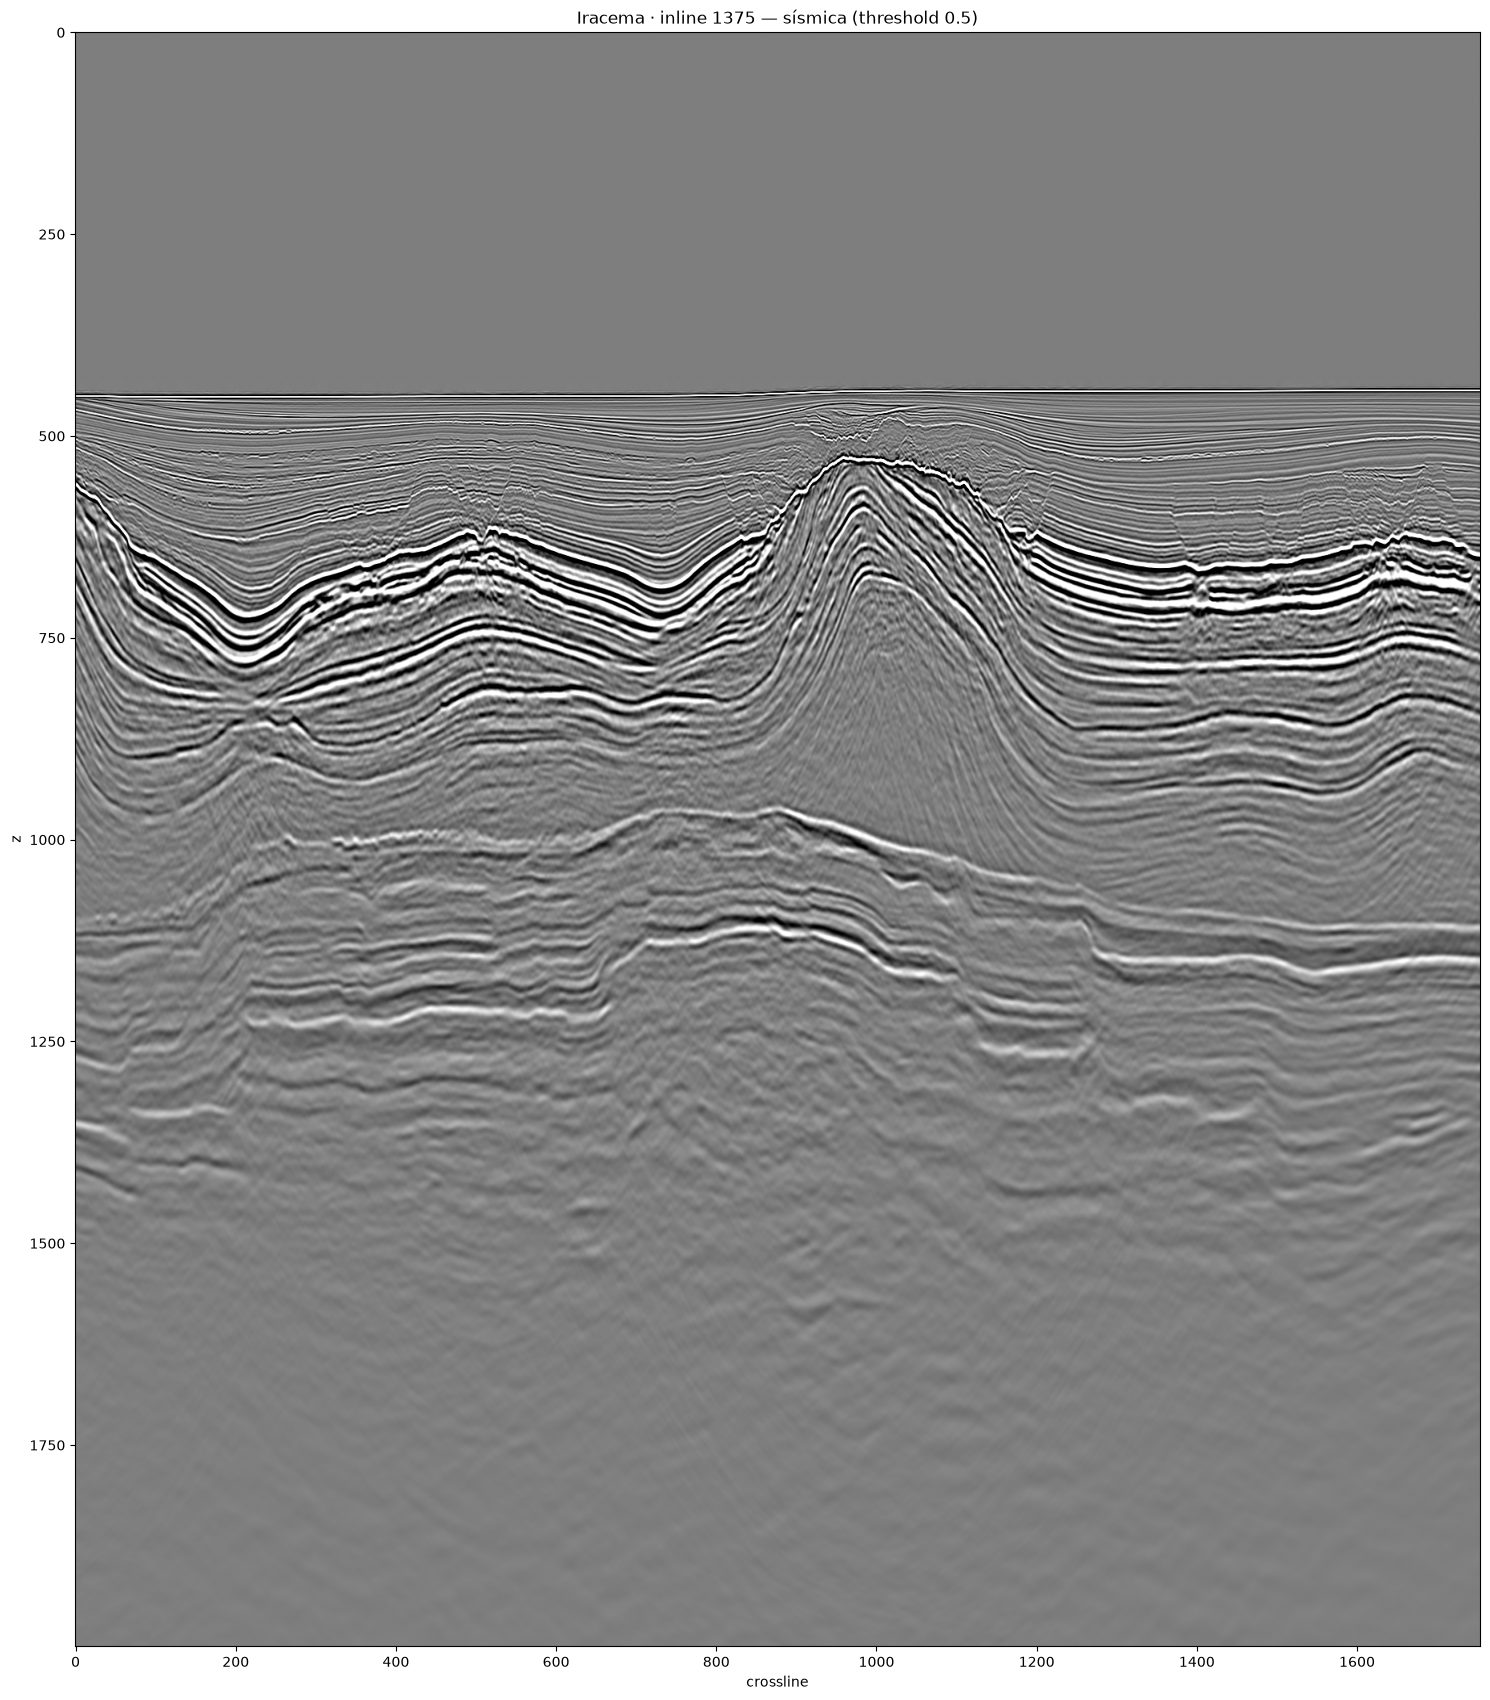

In [9]:
# INLINE DO BLOCO DE IRACEMA: MONTA A PREDIÇÃO, EXTRAI OS STICKS E DESENHA OS PAINÉIS
class IracemaSection:
    PANELS = {
        'seismic': [('sísmica', False, False, True)],
        'mask': [('máscara', True, False, True)],
        'sticks': [('sticks', False, True, True)],
        'both': [('sísmica', False, False, False), ('máscara', True, False, True)]
    }

    def __init__(self, preds, inline=INLINE):
        self.preds     = preds
        self.extractor = FaultStickExtractor()
        self.maps      = {}
        self.lines     = {}
        self.seismic   = None
        self.grid      = TileGrid(META_PATH)
        self.shape     = self.grid.shape
        self.inline    = int(inline)

        if not 0 <= self.inline < self.shape[0]:
            raise ValueError(f'inline {self.inline} fora do bloco (0 a {self.shape[0] - 1})')

    # SÍSMICA DA INLINE, DO CACHE QUANDO ELE JÁ EXISTE
    @property
    def background(self):
        if self.seismic is not None:
            return self.seismic

        cache = f'{CACHE_DIR}/real_inline_{self.inline}.npy'

        if not os.path.exists(cache):
            os.makedirs(CACHE_DIR, exist_ok=True)
            np.save(cache, self.grid.reconstruct(IRACEMA_DIR, f'sísmica da inline {self.inline}', inline=self.inline))

        self.seismic = np.load(cache)
        return self.seismic

    # SEÇÃO 2D DE UMA PREDIÇÃO: A INLINE DOS TILES PREDITOS
    def section(self, label):
        if label not in self.maps:
            path = next(p for p in self.preds if p['label'] == label)['path']
            self.maps[label] = self.grid.reconstruct(f'{path}/masks', label, inline=self.inline)

        return self.maps[label]

    # INJETA UMA SEÇÃO JÁ CALCULADA, PARA NÃO REMONTAR A MESMA INLINE DUAS VEZES
    def setSection(self, label, section):
        self.maps[label] = np.asarray(section, np.float32)

    # STICKS DE UMA PREDIÇÃO SOBRE A SÍSMICA DA MESMA INLINE
    def sticks(self, label):
        if label not in self.lines:
            self.lines[label] = self.extractor.extract(self.section(label), seismic=self.background)

        return self.lines[label]

    # RESUMO DA INLINE: QUANTO DELA PASSA DO LIMIAR E O QUE O EXTRATOR TIROU DALI
    def metrics(self, label):
        lengths = np.array([s['len'] for s in self.sticks(label)])
        return {
            'modelo': label,
            'inline': self.inline,
            'fracao_mascara': round(float((self.section(label) >= MODEL_THRESHOLD).mean()), 4),
            'sticks': len(lengths),
            'len_p50': round(float(np.median(lengths)), 1) if len(lengths) else 0.0,
            'len_total': int(lengths.sum()),
            'dip_p50': round(float(np.median([s['dip'] for s in self.sticks(label)])), 1) if len(lengths) else 0.0
        }

    # UMA FIGURA DO PAINEL PEDIDO; save GRAVA EM DISCO EM VEZ DE MOSTRAR
    def show(self, mode='seismic', title=None, save=None):
        panels    = self.PANELS[mode]
        empty     = np.zeros(self.shape[1:])
        seismic   = self.background
        height    = 15 * self.shape[1] / self.shape[2]
        fig, axes = plt.subplots(1, len(panels), figsize=(15 * len(panels), height), squeeze=False)

        for ax, (name, dark, asSticks, draw) in zip(axes[0], panels):
            ax.imshow(empty if dark else seismic, cmap='gray', aspect='auto', zorder=0)
            detail = f'tolerance {self.extractor.tolerance}' if asSticks else f'threshold {MODEL_THRESHOLD}'
            header = name if not draw else f'{name} ({detail})'
            ax.set_title(f'{title} — {header}' if title else header)
            ax.set_xlabel('crossline')
            ax.set_ylabel('z')

            if not draw:
                continue

            self.plotPreds(ax, asSticks)
            ax.set_xlim(-0.5, self.shape[2] - 0.5)
            ax.set_ylim(self.shape[1] - 0.5, -0.5)

            if self.preds:
                ax.legend(handles=[Patch(facecolor=to_rgb(p['color']), label=p['label']) for p in self.preds], loc='upper right', framealpha=0.9)

        plt.tight_layout()

        if save:
            os.makedirs(os.path.dirname(save), exist_ok=True)
            plt.savefig(save, dpi=200, bbox_inches='tight')
            plt.close(fig)
            return print(f'figura salva em {save}')

        plt.show()

    # AS PREDIÇÕES SOBRE O PAINEL: MÁSCARA OU STICKS
    def plotPreds(self, ax, asSticks):
        for i, p in enumerate(self.preds):
            color, z = to_rgb(p['color']), 2 + i

            if asSticks:
                for s in self.sticks(p['label']):
                    ax.plot([s['p0'][0], s['p1'][0]], [s['p0'][1], s['p1'][1]], color=color, lw=1.6, zorder=z)
                continue

            rgba = np.zeros((*self.shape[1:], 4), np.float32)
            rgba[..., :3] = color
            rgba[..., 3]  = self.section(p['label']) >= MODEL_THRESHOLD
            ax.imshow(rgba, aspect='auto', zorder=z)


section = IracemaSection([])
section.show('seismic', title=f'Iracema · inline {section.inline}')

# PREDIÇÃO E FIGURAS POR MODELO
- Para cada modelo: prediz os tiles pendentes (só os da `INLINE`, ou o bloco inteiro com `FULL_PREDICT`), monta a inline, extrai os sticks e grava as três figuras na pasta `iracema/` do modelo (`predicted_seismic_<inline>`, `predicted_mask_<inline>`, `predicted_sticks_<inline>`)
- Com `VOLUME` o bloco predito vira o `predicted.npy` (2751 × 2000 × 1754 em float32, ~38,6 GB, montado direto em disco por memmap), remontado só quando algum tile foi predito agora ou quando ele ainda não existe
- Um modelo com tiles faltando (sem `model.pth`, ou com `scaling` fora de `[0, 1]`) fica fora da tabela; a rede é solta antes do próximo modelo

In [10]:
# MONTA A INLINE PREDITA DO BLOCO, SALVA AS TRÊS FIGURAS E DEVOLVE A LINHA DA TABELA; fresh É QUANTOS TILES ACABARAM DE SER PREDITOS
def predictedBlock(model, fresh):
    blockDir = f'{BASE_PATH}/{model["nome"]}/iracema'
    preds    = [{'label': model['rotulo'], 'path': blockDir, 'color': 'red'}]
    section  = IracemaSection(preds)
    npyPath  = f'{blockDir}/predicted.npy'
    missing  = section.grid.missing(f'{blockDir}/masks', None if VOLUME else section.inline)

    if missing:
        return print(f'[{model["nome"]}] iracema: faltam {len(missing)} tiles em masks/, predição incompleta' + (' (VOLUME pede o bloco inteiro: FULL_PREDICT = True)' if VOLUME else ''))

    if VOLUME and (fresh or not os.path.exists(npyPath)):
        volume = np.lib.format.open_memmap(npyPath, mode='w+', dtype=np.float32, shape=section.shape)
        section.grid.reconstruct(f'{blockDir}/masks', desc=f'{model["nome"]}/iracema', out=volume)
        volume.flush()
        del volume

    if VOLUME:
        section.setSection(model['rotulo'], np.load(npyPath, mmap_mode='r')[section.inline])

    metrics = section.metrics(model['rotulo'])
    title   = f"Iracema (Inline {section.inline}) | Dataset: {str(model['dataset']).upper()} | Modelo: {model['nome']} ({model['rede']})"
    caption = f"{title} | Sticks: {metrics['sticks']}"

    section.show('seismic', title=title, save=f'{blockDir}/predicted_seismic_{section.inline}.png')
    section.show('mask', title=title, save=f'{blockDir}/predicted_mask_{section.inline}.png')
    section.show('sticks', title=caption, save=f'{blockDir}/predicted_sticks_{section.inline}.png')

    run  = json.load(open(f'{blockDir}/predict.json')) if os.path.exists(f'{blockDir}/predict.json') else {}
    info = {key: model[key] for key in ('rede', 'janela', 'iou_teste')}
    return {'modelo': model['nome'], **info, 'overlap': run.get('overlap'), **{k: v for k, v in metrics.items() if k != 'modelo'}}


rows = []

for name in models:
    predictor = IracemaPredictor(name)
    rows.append(predictedBlock(modelSummary(name), predictor.predict()))
    predictor.release()

rows = [row for row in rows if row]
pd.DataFrame(rows)

[model_1] Model Options:
{
    "network": "dbrnet",
    "img_size": [
        128,
        128,
        128
    ],
    "classes": 1,
    "channels": 1,
    "dropout": 0.1,
    "num_filters": 32,
    "lr": 0.001
}
Weights from ../../Documents/Backups/Multiscale//model_1 loaded successfully!

[model_1] iracema: SlidingWindow(janela=(128, 128, 128), tile=(128, 128, 128), overlap=0.25, janelas/tile=1, batch=1) — 38528 tiles pendentes
[model_1] janela == tile: uma passada por tile — OVERLAP=0.25 e o peso Hann não têm efeito aqui


model_1 - iracema: 100%|█████████▉| 38527/38528 [2:04:02<00:00,  5.18it/s]  


Predições de model_1 - iracema salvas em ../../Documents/Backups/Multiscale//model_1/iracema/masks


model_1 · dbrnet 128×128×128 (iou=0.757): 100%|██████████| 896/896 [00:03<00:00, 246.03it/s]


figura salva em ../../Documents/Backups/Multiscale//model_1/iracema/predicted_seismic_1375.png
figura salva em ../../Documents/Backups/Multiscale//model_1/iracema/predicted_mask_1375.png
figura salva em ../../Documents/Backups/Multiscale//model_1/iracema/predicted_sticks_1375.png


,modelo,rede,janela,iou_teste,overlap,inline,fracao_mascara,sticks,len_p50,len_total,dip_p50
0,model_1,dbrnet,128×128×128,0.7568,0.25,1375,0.0153,56,249.5,15345,66.6


# FIGURAS E TABELA NA RAIZ
- As três figuras de cada modelo são copiadas para `OUTPUT_DIR` (`<BASE_PATH>/outputs/iracema`) com o modelo e a rede no nome, para comparar os modelos selecionados lado a lado sem abrir pasta por pasta
- A tabela `sticks_report.csv` fica na mesma pasta e junta as linhas novas às do CSV anterior: um par (modelo, inline) recalculado substitui o antigo, e rede, janela e IoU de teste são relidos do `info.json`

In [11]:
REPORT_PATH = f'{OUTPUT_DIR}/sticks_report.csv'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for row in rows:
    for kind in ('seismic', 'mask', 'sticks'):
        shutil.copy(f'{BASE_PATH}/{row["modelo"]}/iracema/predicted_{kind}_{row["inline"]}.png', f'{OUTPUT_DIR}/{row["modelo"]}_{row["rede"]}_inline_{row["inline"]}_{kind}.png')

report   = pd.DataFrame(rows)
done     = set(zip(report.modelo, report.inline))
previous = pd.read_csv(REPORT_PATH, dtype={'inline': int}) if os.path.exists(REPORT_PATH) else pd.DataFrame(columns=report.columns)
previous = previous.loc[[key not in done for key in zip(previous.modelo, previous.inline)]].copy()

for column in ('rede', 'janela', 'iou_teste'):
    previous[column] = [modelSummary(name)[column] for name in previous.modelo]

report = pd.concat([frame for frame in (report, previous) if len(frame)], ignore_index=True).sort_values(['inline', 'sticks'], ascending=[True, False]).reset_index(drop=True)
report.to_csv(REPORT_PATH, index=False)
print(f'{3 * len(rows)} figuras e a tabela em {OUTPUT_DIR}')
report

3 figuras e a tabela em ../../Documents/Backups/Multiscale//outputs/iracema


,modelo,rede,janela,iou_teste,overlap,inline,fracao_mascara,sticks,len_p50,len_total,dip_p50
0,model_5,fault_edge_former,128×128×128,0.6296,0.25,1375,0.0425,72,200.0,16793,65.8
1,model_6,fault_seg_net,128×128×128,0.7541,0.25,1375,0.0611,68,228.0,17820,64.3
2,model_1,dbrnet,128×128×128,0.7568,0.25,1375,0.0153,56,249.5,15345,66.6
3,model_2,dbrnet,128×128×128,0.7313,0.25,1375,0.0132,55,214.0,12993,67.5
4,model_3,macnn,128×128×128,0.7295,0.25,1375,0.0142,52,202.6,11002,64.7
5,model_4,nru_net,128×128×128,0.7252,0.25,1375,0.0111,44,179.5,9438,65.7


In [12]:
p = IracemaPredictor('model_1')
print("Caminho do modelo existe?", os.path.exists(p.modelPath))
print("model.pth existe?", os.path.exists(f"{p.modelPath}/model.pth"))
print("Tiles de entrada faltando em files/patches:", len(p.grid().missing(IRACEMA_DIR, p.inline)))

Caminho do modelo existe? True
model.pth existe? True
Tiles de entrada faltando em files/patches: 0
